# Neural Decoding
In this notebook, we explore basic techniques for decoding stimuli from neural spike trains.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
%matplotlib inline

## 1. Simulating Spike Trains for Two Stimuli
We generate synthetic spike counts for a neuron responding to two different visual stimuli (e.g., gratings at 0 degrees vs 90 degrees).

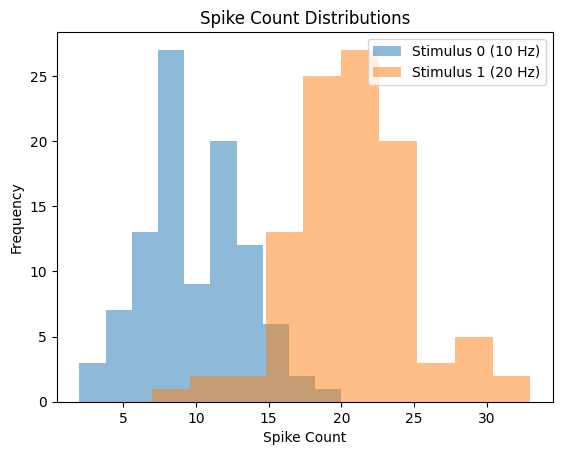

In [2]:
# Parameters
n_trials = 100
# Stimulus 0: mean spike count = 10
# Stimulus 1: mean spike count = 20

# Generate data
spikes_0 = np.random.poisson(10, n_trials)
spikes_1 = np.random.poisson(20, n_trials)

X = np.concatenate([spikes_0, spikes_1]).reshape(-1, 1)
y = np.concatenate([np.zeros(n_trials), np.ones(n_trials)])

plt.hist(spikes_0, alpha=0.5, label='Stimulus 0 (10 Hz)')
plt.hist(spikes_1, alpha=0.5, label='Stimulus 1 (20 Hz)')
plt.xlabel('Spike Count')
plt.ylabel('Frequency')
plt.legend()
plt.title('Spike Count Distributions')
plt.show()

## 2. Decoding using Logistic Regression
We train a simple classifier to predict which stimulus was presented based on the spike count.

In [3]:
# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train model
model = LogisticRegression()
model.fit(X_train, y_train)

# Predict and evaluate
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f'Decoding Accuracy: {accuracy * 100:.2f}%')

Decoding Accuracy: 95.00%
